# Project 20: Push Test Data Pipeline + Dashboard
Data simulasi. Notebook membaca CSV hasil pipeline; angka tidak dihitung ulang.

In [1]:
from pathlib import Path
import pandas as pd
R1 = Path('..') / '1-data-preparation'
R2 = Path('..') / '2-analysis'
rd = lambda n, d=R2: pd.read_csv(d / n)


## Q1 dan Q11: pemuatan file dan ground truth

In [2]:
print('ingest_attempts.csv'); display(rd('ingest_attempts.csv', R1))

ingest_attempts.csv


,percobaan,file_dibaca,loaded,quarantined,skipped
0,1,1214,1141,59,14
1,2,1214,0,0,1214


In [3]:
print('ground_truth_files.csv'); display(rd('ground_truth_files.csv', R2))

ground_truth_files.csv


,jenis,ditanam,terdeteksi,tidak_terdeteksi
0,format mesin baru,18,18,0
1,file terpotong (bukan format baru),23,21,2
2,file terpotong yang juga format baru,1,1,0
3,file kosong,10,10,0
4,kolom hilang (tanpa kolom Force),10,10,0
5,salinan ganda (nama copy_of_),14,14,0
6,format angka titik/koma lain (tidak rusak),36,36,0


In [4]:
print('ground_truth_normal.csv'); display(rd('ground_truth_normal.csv', R2))

ground_truth_normal.csv


,file_normal,file_normal_dimuat,file_normal_salah_karantina,file_rusak_ditanam,file_rusak_lolos_dimuat,file_dikarantina
0,1139,1139,0,61,2,59


## Q2 dan Q3: rekonsiliasi dengan proses lama

In [5]:
print('macro_summary.csv'); display(rd('macro_summary.csv', R2))

macro_summary.csv


,file_di_folder,file_macro_gagal_format_baru,file_terpotong_terbaca_sebagian,file_salinan_terbaca_dua_kali,nilai_pipeline,nilai_berubah,persen_nilai_berubah,file_terdampak,file_dimuat_pipeline,nilai_macro_total,nilai_macro_dari_salinan,nilai_macro_dari_file_terpotong,selisih_nilai_macro_vs_pipeline,rata_nilai_berubah_macro,rata_nilai_berubah_pipeline
0,1214,19,19,13,13900,424,0.030504,36,1141,14441,158,30,541,7.616629,7616.628774


In [6]:
print('macro_group_compare.csv'); display(rd('macro_group_compare.csv', R2))

macro_group_compare.csv


,model,condition,ukuran,pipeline,macro,selisih
0,Model A,after_oven,n,3401.000000,3528.000000,127.000000
1,Model A,after_oven,mean_g,8581.919288,8305.549713,-276.369576
2,Model A,after_oven,min_g,5702.600000,-3058.000000,-8760.600000
3,Model A,after_oven,max_g,11722.800000,29472.300000,17749.500000
4,Model A,after_oven,cpk,2.734510,0.902263,-1.832247
5,Model A,after_oven,oos_rate,0.000000,0.054138,0.054138
6,Model A,before_oven,n,3721.000000,3892.000000,171.000000
7,Model A,before_oven,mean_g,7151.974872,7057.344121,-94.630751
8,Model A,before_oven,min_g,3818.400000,-442.000000,-4260.400000
9,Model A,before_oven,max_g,10086.300000,29954.300000,19868.000000


In [7]:
print('macro_session_compare.csv'); display(rd('macro_session_compare.csv', R2))

macro_session_compare.csv


,ukuran,sesi,sesi_beda,persen,selisih_abs_maks
0,mean,1141,36,0.031551,9129.19167
1,min,1141,36,0.031551,7931.56050
2,max,1141,36,0.031551,10871.51760


## Q4 dan Q5: Cpk dan out-of-spec

In [8]:
print('cpk_group.csv'); display(rd('cpk_group.csv', R2))

cpk_group.csv


,peringkat,model,condition,n,sesi,mean_g,sd_g,cpk,cpk_ci_low,cpk_ci_high,jarak_ke_lsl_sd,di_bawah_cpk_target,n_cukup,oos_n,oos_rate,oos_ci_low,oos_ci_high,batas_atas_aturan_tiga
0,1,Model B,before_oven,3366,277,6758.616904,1679.495257,1.043690,1.016711,1.070907,3.131070,1,1,4,0.001188,4.622142e-04,0.003052,0.000891
1,2,Model A,before_oven,3721,304,7151.974872,887.061436,2.123857,2.071655,2.178681,6.371571,0,1,0,0.000000,1.084202e-19,0.001031,0.000806
2,3,Model B,after_oven,3412,281,8300.667233,883.882620,2.564695,2.504053,2.624848,7.694084,0,1,0,0.000000,1.084202e-19,0.001125,0.000879
3,4,Model A,after_oven,3401,279,8581.919288,863.277028,2.734510,2.670942,2.799637,8.203530,0,1,0,0.000000,0.000000e+00,0.001128,0.000882


In [9]:
print('kpi_group.csv'); display(rd('kpi_group.csv', R2))

kpi_group.csv


,model,condition,sesi,n,mean_g,min_g,max_g,sd_g,lsl_g,usl_g,cpu,cpl,cpk,oos_rate
0,Model A,after_oven,279,3401,8581.919288,5702.6,11722.8,863.277028,1500.0,19000.0,4.022687,2.734510,2.734510,0.000000
1,Model A,before_oven,304,3721,7151.974872,3818.4,10086.3,887.061435,1500.0,19000.0,4.452163,2.123857,2.123857,0.000000
2,Model B,after_oven,281,3412,8300.667233,4811.1,11388.2,883.882620,1500.0,19000.0,4.034975,2.564695,2.564695,0.000000
3,Model B,before_oven,277,3366,6758.616904,543.8,12351.0,1679.495257,1500.0,19000.0,2.429576,1.043690,1.043690,0.001188


## Q6 sampai Q8: shift, mesin, tren, pergeseran

In [10]:
print('shift_machine_test.csv'); display(rd('shift_machine_test.csv', R2))

shift_machine_test.csv


,faktor,kelompok_a,kelompok_b,sesi_a,sesi_b,median_resid_a,median_resid_b,selisih_rata_g,p_mannwhitney
0,shift,Shift 1,Shift 2,615,526,22.180892,15.567122,-0.178288,0.944609
1,machine_id,PT-01,PT-02,549,592,42.345947,3.496368,-69.173020,0.035881


In [11]:
print('weekly_all.csv'); display(rd('weekly_all.csv', R2))

weekly_all.csv


,iso_week,n,mean_g,sd_g,cpk,n_cukup
0,2026-W14,863,7746.839977,1313.302999,1.585529,1
1,2026-W15,1033,7688.840271,1297.291616,1.590195,1
2,2026-W16,1110,7740.627207,1363.843546,1.525255,1
3,2026-W17,1229,7668.170708,1381.015855,1.488800,1
4,2026-W18,1013,7686.017374,1316.471838,1.566312,1
5,2026-W19,902,7767.498780,1361.532788,1.534422,1
6,2026-W20,1178,7806.205772,1380.899479,1.522246,1
7,2026-W21,940,7632.829574,1385.837454,1.475120,1
8,2026-W22,1133,7497.668667,1472.573565,1.357639,1
9,2026-W23,979,7643.058631,1330.713964,1.538788,1


In [12]:
print('changepoint.csv'); display(rd('changepoint.csv', R2))

changepoint.csv


,machine_id,sesi,tanggal_mulai,tanggal_selesai,sesi_di_luar,sesi_di_jendela,rata_luar_resid,rata_jendela_resid,selisih_g,persen_dari_rata,t_welch,p_permutasi
0,PT-01,549,2026-04-22,2026-04-28,499,50,21.410443,180.395383,158.984940,0.020576,3.075131,0.154845
1,PT-02,592,2026-05-23,2026-05-29,549,43,25.398427,-782.495727,-807.894153,-0.105501,14.171670,0.000999


## Q9 dan Q10: waktu dihemat (estimated)

In [13]:
print('impact.csv'); display(rd('impact.csv', R2))

impact.csv


,menit_per_file,dasar,file_dimuat_periode,file_karantina_periode,file_per_tahun,menit_dihemat_per_file,menit_hemat_periode,jam_hemat_periode,jam_hemat_per_tahun,label
0,3,0,1141,59,4576.538462,3,3423,57.050000,228.826923,estimated
1,5,1,1141,59,4576.538462,5,5705,95.083333,381.378205,estimated
2,10,0,1141,59,4576.538462,10,11410,190.166667,762.756410,estimated


## Q12: idempoten dan tes

In [14]:
print('idempotency.csv'); display(rd('idempotency.csv', R2))

idempotency.csv


,tabel,setelah_percobaan_1,setelah_percobaan_2,tambahan
0,test_run,1141,1141,0
1,measurement,14253,14253,0
2,ingest_log,1214,2428,1214


In [15]:
print('pytest_result.csv'); display(rd('pytest_result.csv', R2))

pytest_result.csv


,tes,hasil
0,test_normal_file,lulus
1,test_thousand_separator_us_format,lulus
2,test_dot_thousand_comma_decimal,lulus
3,test_new_machine_format_goes_to_quarantine,lulus
4,test_empty_file,lulus
5,test_truncated_file,lulus
6,test_missing_header_field,lulus
7,test_non_numeric_value,lulus
8,test_out_of_range_values_flagged,lulus
9,test_duplicate_and_idempotent,lulus


## Cek silang dan lima fakta rancangan

In [16]:
print('crosscheck.csv'); display(rd('crosscheck.csv', R2))

crosscheck.csv


,cek,item,dibandingkan,cocok
0,SQL vs pandas (parser independen),per sesi: n,1141,1141
1,SQL vs pandas (parser independen),per sesi: mean_g,1141,1141
2,SQL vs pandas (parser independen),per sesi: min_g,1141,1141
3,SQL vs pandas (parser independen),per sesi: max_g,1141,1141
4,SQL vs pandas (parser independen),per sesi: sd_g,1141,1141
...,...,...,...,...
194,SQL vs Excel (LibreOffice),sesi PT-02_20260624_Shift2_ModelA_b: n,1,1
195,SQL vs Excel (LibreOffice),sesi PT-02_20260624_Shift2_ModelA_b: mean_g,1,1
196,SQL vs Excel (LibreOffice),sesi PT-02_20260624_Shift2_ModelA_b: min_g,1,1
197,SQL vs Excel (LibreOffice),sesi PT-02_20260624_Shift2_ModelA_b: max_g,1,1


In [17]:
print('design_facts.csv'); display(rd('design_facts.csv', R2))

design_facts.csv


,fakta,rancangan,ukuran,nilai,nilai2,keterangan,kombinasi
0,1,satu kombinasi dibuat bervariasi besar sehingg...,Cpk terendah,1.043690,1.000000,"kombinasi di bawah 1,33",Model B before_oven
1,2,rata-rata satu mesin turun sekitar 800 g selam...,selisih rata-rata jendela PT-02 terhadap di lu...,-807.894153,1.000000,tanggal mulai jendela sama dengan tanggal tert...,NaN
2,3,sekitar 3% file berformat titik ribuan dan kom...,persen file dengan format angka lain,0.030000,36.000000,file tertanam,NaN
3,4,"file bermasalah: header berbeda, kolom hilang,...",jenis file bermasalah tertanam,76.000000,14.000000,file bermasalah tertanam (salinan),NaN
4,5,"2% sampai 3% nilai tidak wajar (0, negatif, di...",persen hasil ukur tidak valid di file yang dimuat,353.000000,0.024767,baris tidak valid terdeteksi,353


Rata-rata mingguan semua mesin

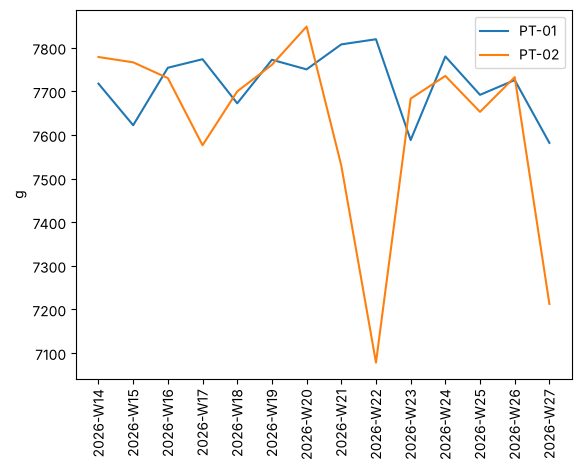

In [18]:
import matplotlib.pyplot as plt
d = rd('weekly_machine.csv'); [plt.plot(g.iso_week, g.mean_g, label=m) for m, g in d.groupby('machine_id')]
plt.xticks(rotation=90); plt.legend(); plt.ylabel('g'); plt.show()